# easyspec tutorial 3: an exoplanet transit with differential photometry

When a planet passes in front of its star, the star gets fainter by (Rp/Rs)², where Rp and Rs are the radii of the planet and of the
star: about 1% for a Jupiter in front of the Sun. To see it from the ground we need relative precisions of ~1 part per thousand (1 ppt =
0.1%), much better than the stability of the atmosphere. The trick is **differential photometry**: the target is compared, frame by frame,
with other stars of the same field, which suffer the same clouds, extinction and seeing.

We use the time series data in `transit_V/` of `easyspec_photometry_synthetic_transit/`: 120 exposures of 60 s in V (5 hours), defocused (bright
stars), read out in a 512 x 512 window of the detector, with the bias and flat frames taken in the same mode (`transit_bias/`,
`transit_flats_V/`).


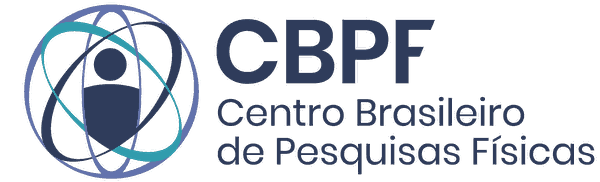

In [1]:
from pathlib import Path
from easyspec.cleaning import cleaning
from easyspec.photometry import photometry

data = Path("easyspec_photometry_synthetic_transit")
out = Path("photometry_output")
out.mkdir(exist_ok=True)

## 1. Reduction with `cleaning`

The usual steps, without combining or aligning the frames: each frame is a point of the light curve, and the photometry follows the
stars as they drift on the detector (resampling would correlate the noise of the pixels).

(If your bias and flats were full frames and only the science frames were windowed, `photometry.crop_to_detector_window()` cuts the
masters to the window.)

In [2]:
c = cleaning()

# Folders
bias_folder = data/"transit_bias"
flat_folder = data/"transit_flats_V"
transit_folder = data/"transit_V"

# Read the raw frames
raw = c.data_paths(bias=str(bias_folder), flats=str(flat_folder), targets=str(transit_folder))

# Remove the overscan columns
trimmed = c.trim(raw, x1=0, x2=512, y1=0, y2=512)

# Bias
master_bias = c.master("bias", trimmed, plot=False)
debiased = c.debias(trimmed, master_bias)

# Flat field
master_flat = c.master("flat", debiased, plot=False)
norm_flat = c.norm_master_flat(master_flat, method="imaging", plots=False)
flattened = c.flatten(debiased, norm_flat)

# ADU -> electrons, cosmic rays, and the variance of every pixel (gain and read noise read from the header of each frame)
electrons = c.gain_correct(flattened, gain_header_entry="GAIN", verbose=False)
cleaned = c.remove_cosmic_rays(electrons, readnoise_header_entry="RDNOISE", verbose=False)
variance, mask = c.compute_variance(cleaned, readnoise_header_entry="RDNOISE", verbose=False)

# Save every frame individually: each frame is one point of the light curve (no alignment, no combination)
c.save_fits_files(cleaned, out/"transit_V", Type="target", variance=variance, mask=mask)

Normalized master flat: 512/512 illuminated rows; median = 0.9926; robust scatter = 0.0127; 0 pixels set to 1 (low signal).
1 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.25%, from 0.24% to 0.25% depending on the column.


A look at the first reduced frame: the stars are big disks because the telescope was defocused on purpose (the light of the bright
target is spread over many pixels, so it does not saturate and the flat-field errors average out). The target is the bright star near the center.

120 images loaded (bands: ['V'], 512x512 px).


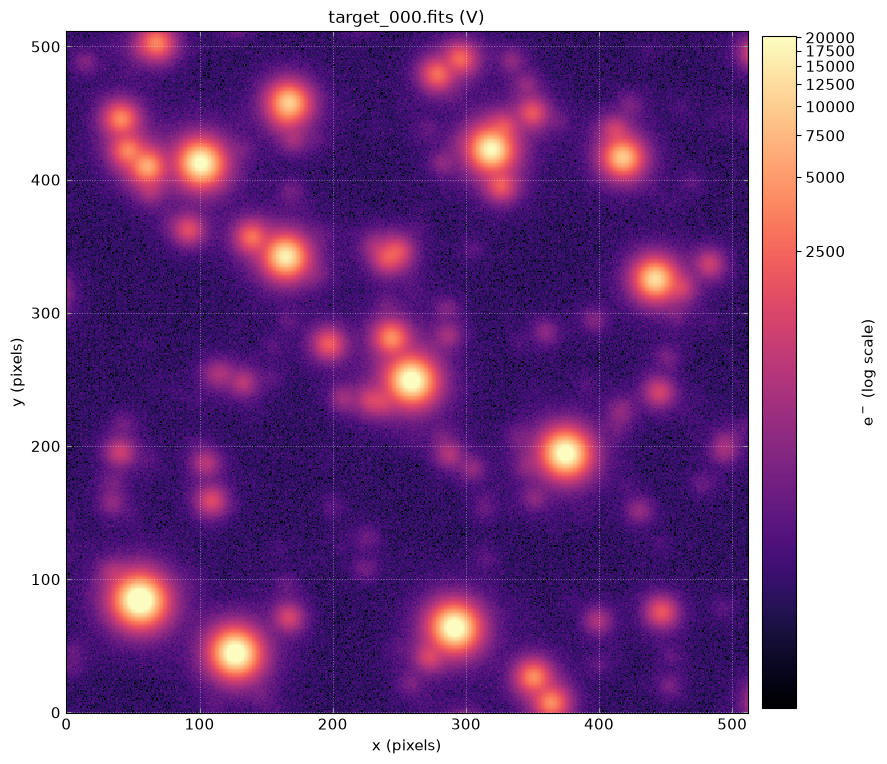

<Axes: title={'center': 'target_000.fits (V)'}, xlabel='x (pixels)', ylabel='y (pixels)'>

In [3]:
phot = photometry()
frames = phot.load_images(out/"transit_V")
phot.plot_image(frames[0], image_scale="log")                     # image_scale="log" (default) or "linear"

## 2. Differential photometry

`differential_photometry()` builds the light curve automatically:

1. **Registration**: the stars are detected in every frame and the drift of the field is found relative to a reference frame.
2. **Measurements**: every star of the reference frame is measured in every frame, in apertures from 0.6 to 2.5 FWHM, with a local sky.
   Defocused stars are big (FWHM ~16 pixels here), so the apertures scale with the FWHM.
3. **Comparison ensemble**: stars measured in all frames, not saturated, and not much fainter than the target. Each comparison is
   checked against the others, and the noisiest ones (variable stars, bad pixels) are removed. The ensemble is the weighted sum of the
   comparisons (brighter, less noisy stars weigh more).
4. **Light curve**: target / ensemble, normalized. Frames with thick clouds (transparency below 70%) or where a comparison jumps (cosmic
   ray, satellite) are rejected.
5. **Aperture**: the one giving the smallest point-to-point scatter. This criterion does not depend on the transit (a slow dip barely
   changes the differences between consecutive points), so it does not bias the depth.
6. **Times**: mid-exposure, in BJD_TDB (barycentric Julian date in the TDB scale: the time at the barycentre of the Solar System, which
   removes the up-to-8-minute light-travel delays as the Earth moves around the Sun). It needs the coordinates of the target (from the WCS)
   and of the observatory (from the header).

The target must be given, by its position in the reference frame or by `target_coordinates=(ra, dec)`: there is no automatic choice
(the brightest star of the field is not necessarily the target).

**How the comparison stars are chosen** (`comparison_stars="auto"`, the default): the candidates are the stars of the reference frame
measured in at least 90% of the frames (stars too close to the edges, whose sky annulus falls outside the image, are excluded), never
close to saturation and not fainter than 10% of the target. Each candidate is divided by the sum of the others; the noisiest one, relative
to its photon noise, is removed, and the test is repeated until no candidate is more than twice as noisy as the median.

The plot below (made by `differential_photometry()`, or later with `phot.plot_differential_photometry(light_curve)`) shows the target in
red, with its aperture and sky annulus, the comparison stars in green, and the other stars in grey, all numbered.

/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/photometry/aux_differential_photometry.py:183: RuntimeWarning: All-NaN slice encountered
  brightness = np.nanmedian(fluxes[target_measured, :, middle_radius], axis=0)


Differential photometry of 120 frames (reference target_032.fits, median FWHM 15.8 px): target at (262.8, 246.0); 5 comparison stars (of 5 candidates); aperture 1.0 FWHM = 15.8 px; 119 frames used; scatter 0.46 ppt per frame (expected from photon noise 0.45 ppt); comparison-star systematics 0.06 ppt; time scale BJD_TDB


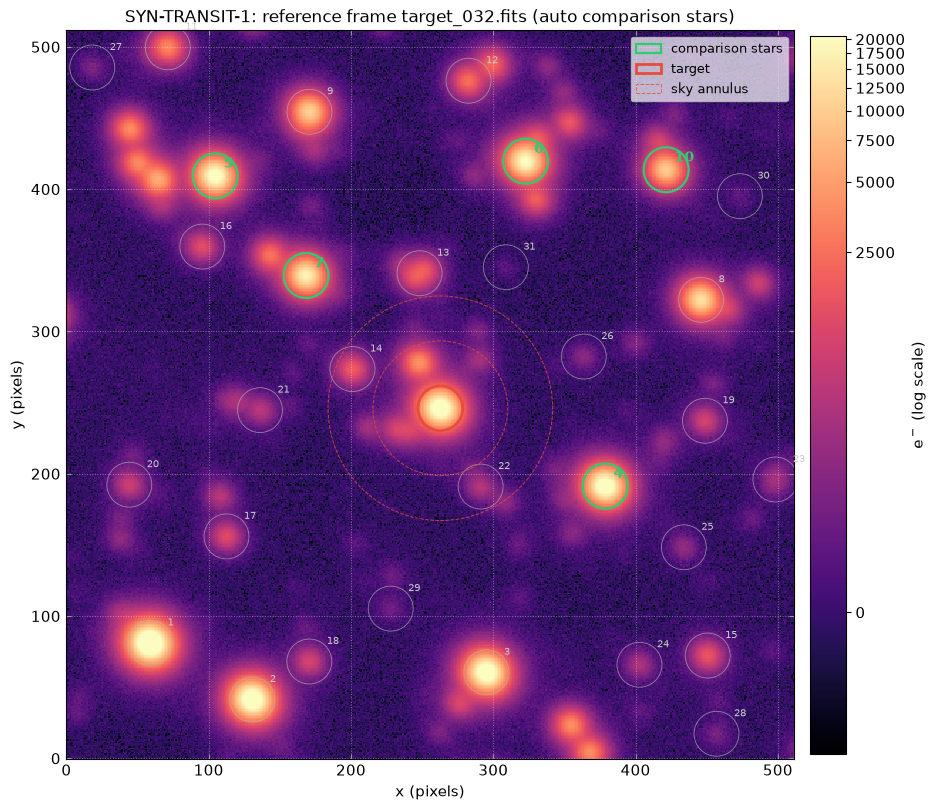

In [4]:
light_curve = phot.differential_photometry(frames,
                                           target_position=(259, 248),        # (x, y) of the target in the reference frame
                                           target_coordinates=None,           # or (ra, dec) in degrees (needs a WCS)
                                           comparison_stars="auto",           # or a list of star numbers / (x, y) positions
                                           aperture_radii=None,               # radii to try, in FWHM (default: 0.6 to 2.5)
                                           sky_annulus=(3.0, 5.0),            # inner and outer radius of the sky annulus, in FWHM
                                           minimum_comparison_brightness=0.1, # comparisons fainter than 10% of the target are not used
                                           minimum_transparency=0.7,          # frames with clouds (< 70% of the median flux) are rejected
                                           time_scale="auto",                 # BJD_TDB if possible; or "bjd_tdb", "mjd_utc", "jd_utc"
                                           detection_threshold=10.0,          # detection threshold (sigma) for the registration
                                           plot=True,                         # reference frame with the target and the comparisons
                                           image_scale="log",
                                           verbose=True)

To choose the comparison stars yourself, give their numbers in the plot above, or their positions (x, y) in the reference frame (or
`SkyCoord` coordinates). All of them are used, and the noise of each one relative to the photon noise is printed, so that a variable star
can be spotted:

```python
light_curve = phot.differential_photometry(frames, target_position=(259, 248), comparison_stars=[4, 5, 7, 10])
```

The light curve, with the diagnostics of the observing conditions:

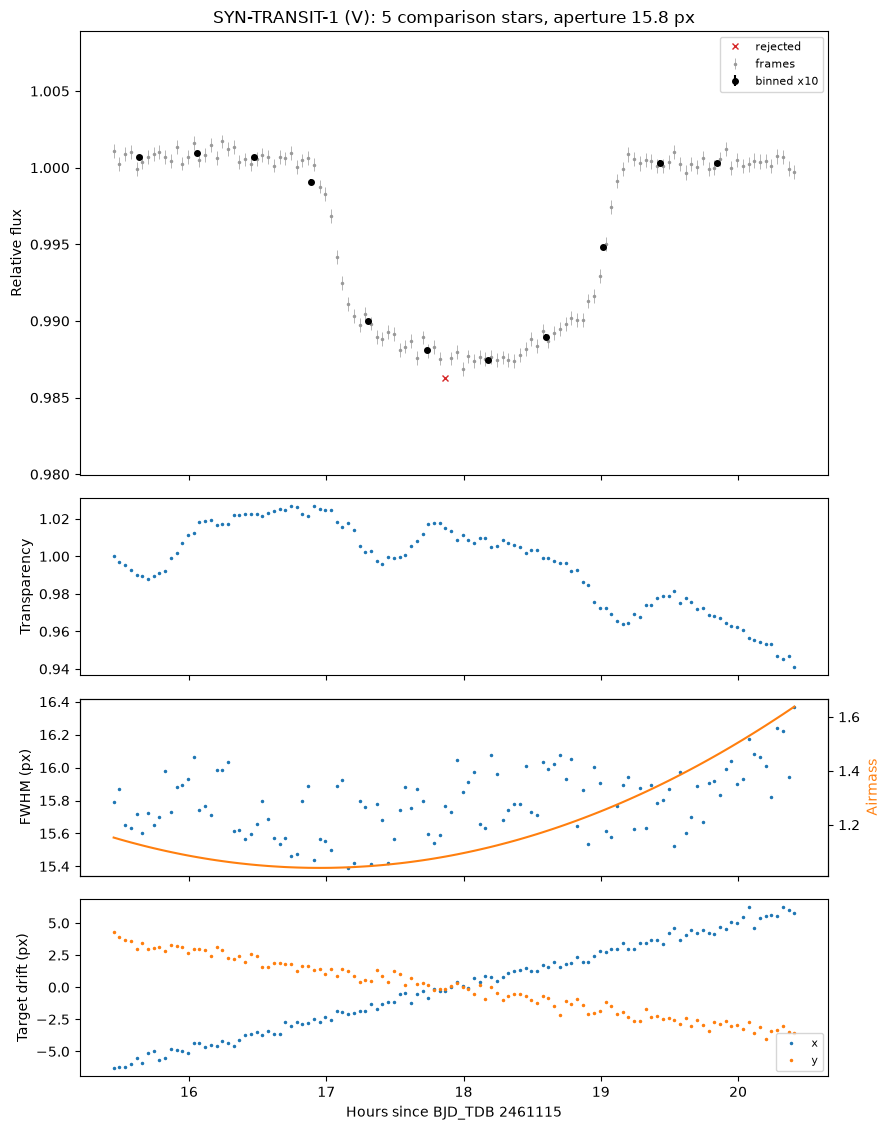

In [5]:
phot.plot_light_curve(light_curve,
                      number_of_points_per_bin=10,   # the black points are averages of 10 frames
                      show_diagnostics=True,         # transparency, FWHM and airmass, and drift of the target below the light curve
                      title=None)                    # default: object, band, number of comparisons and aperture

Check the diagnostics below the light curve: the transparency (thin clouds), the FWHM and airmass, and the drift of the target on the
detector. A dip that coincides with a jump in one of them is suspicious.

## 3. Transit fit

The model is the light curve of a star with **limb darkening** (the edge of the stellar disk is darker than the centre, which rounds the
bottom of the transit) partly covered by a planet on a circular orbit. Its parameters:

- **Tc**, the mid-transit time;
- **Rp/Rs**, the planet-to-star radius ratio (depth ≈ (Rp/Rs)²);
- **a/Rs**, the orbital semi-major axis in stellar radii (sets the duration together with the period);
- **b**, the impact parameter: the projected distance between the planet's path and the center of the star, in stellar radii (sets the
  shape of ingress and egress);
- the period (fixed: one transit cannot measure it) and the quadratic limb-darkening coefficients (fixed here to theoretical values for
  the V band; they can be fitted with priors).

The transit is multiplied by a **baseline**: a straight line in time plus a term in airmass, because the target and the comparisons have
different colors and the atmosphere dims blue stars more. The baseline coefficients are solved at every step of the fit.

The uncertainties come from an MCMC (emcee). Before it, the errors are rescaled by the reduced χ² and by the **red-noise factor** β: if
the residuals are correlated in time (e.g. slow systematics), averaging them in bins reduces them less than white noise would, and the
errors are increased accordingly. The ΔBIC compares the models with and without the transit (ΔBIC > 10 is a strong detection).

Transit fit: 119 points; errors scaled by 0.89 (reduced chi2 0.80, red-noise factor 1.00); Delta BIC (no transit - transit) = 8687.9; residual rms 0.39 ppt
   Mid-transit time (BJD_TDB)         2461115.751774 +0.000132 -0.000127
   Rp/Rs                              0.1036 +0.0012 -0.0011
   Depth (Rp/Rs)^2                    0.0107 +0.0002 -0.0002
   a/Rs                               11.4284 +0.4397 -0.3997
   Impact parameter b                 0.3065 +0.0889 -0.1579
   Inclination (deg)                  88.4635 +0.8190 -0.5178
   Duration T14 (h)                   2.2852 +0.0204 -0.0197
   u1                                 0.4400 +0.0000 -0.0000
   u2                                 0.2200 +0.0000 -0.0000


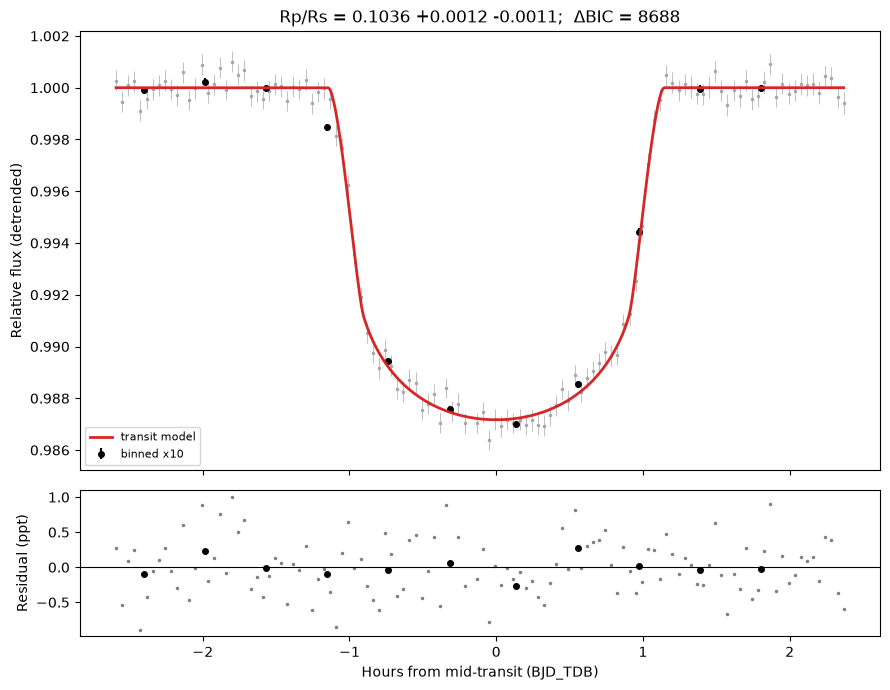

In [6]:
transit = phot.fit_transit(light_curve,
                           period=3.217,                      # days, fixed: a single transit cannot measure it
                           mid_transit_time=None,             # first guess of Tc; None: the minimum of the smoothed light curve
                           planet_radius=0.1,                 # first guess of Rp/Rs
                           scaled_semi_major_axis=10,         # first guess of a/Rs
                           impact_parameter=0.3,              # first guess of b
                           limb_darkening=(0.44, 0.22),       # quadratic coefficients (u1, u2) for the V band
                           fit_limb_darkening=False,          # True: fit them, with Gaussian priors around these values
                           limb_darkening_prior_width=0.1,    # width of those priors
                           fixed_parameters=None,             # e.g. {"impact_parameter": 0.4} (needed for partial transits)
                           baseline_polynomial_order=1,       # baseline: straight line in time...
                           airmass_term=True,                 # ... plus a term in airmass (differential extinction)
                           extra_regressors=None,             # e.g. ["fwhm"]: other columns of the light curve in the baseline
                           number_of_walkers=32,              # MCMC (emcee) settings
                           number_of_steps=4000,
                           burn_in_fraction=0.4,              # fraction of the steps discarded at the beginning
                           seed=1,                            # same random numbers in every run (reproducible results)
                           plot=True,
                           verbose=True)

The synthetic planet has Rp/Rs = 0.105, a/Rs = 11 and b = 0.40: compare them with the fitted values above. The residuals (lower panel)
should look like white noise: the scatter per frame is printed by `differential_photometry()` and can be compared with the photon noise.

## 4. Making your own plots

All the numbers behind the plots above are returned, so you can make your own figures. `light_curve` is a table with one row per frame
(time, relative flux and its error, airmass, FWHM, sky, position of the target, transparency, and `used`, which is False for the
rejected frames). For example, the raw light curve with the airmass below it:

['time', 'relative_flux', 'relative_flux_error', 'airmass', 'fwhm', 'sky', 'x', 'y', 'transparency', 'used', 'image']


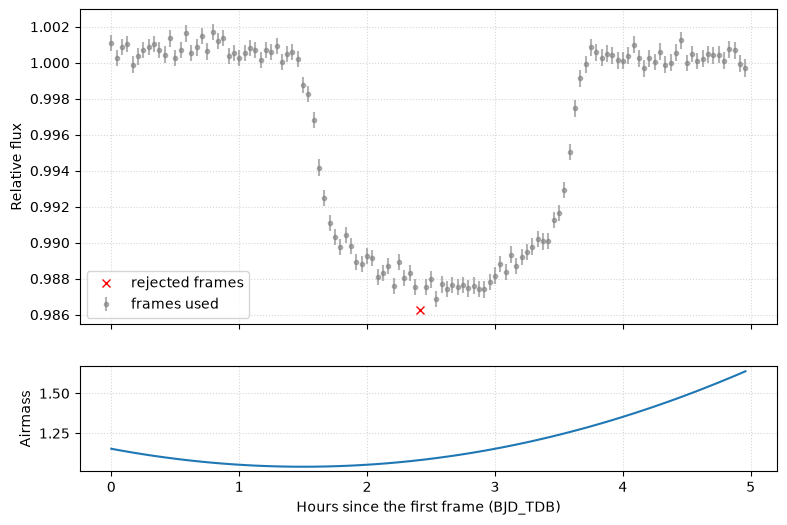

In [7]:
import matplotlib.pyplot as plt

# light_curve is an astropy Table, one row per frame
print(light_curve.colnames)
used = light_curve["used"]                                # False for frames rejected (clouds, cosmic rays, ...)
hours = (light_curve["time"] - light_curve["time"][0])*24   # time in hours since the first frame

figure, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.errorbar(hours[used], light_curve["relative_flux"][used], yerr=light_curve["relative_flux_error"][used], fmt=".",
             color="gray", alpha=0.6, label="frames used")
top.plot(hours[~used], light_curve["relative_flux"][~used], "x", color="red", label="rejected frames")
top.set_ylabel("Relative flux")
top.legend()
bottom.plot(hours, light_curve["airmass"], color="C0")
bottom.set_ylabel("Airmass")
bottom.set_xlabel(f"Hours since the first frame ({light_curve.meta['time_scale']})")
for axis in (top, bottom):
    axis.grid(linestyle=":", alpha=0.5)
plt.show()

`transit` is a dictionary: `transit["parameters"]` holds the fitted and derived parameters as (median, upper error, lower error), and
`transit["time"]`, `transit["flux"]`, `transit["baseline"]` and `transit["transit_model"]` hold the frames used in the fit, the fitted
baseline and the transit model at the same times. Dividing the data by the baseline gives the detrended light curve:

mid_transit_time          2461115.75177  +0.00013 -0.00013
planet_radius             0.10356  +0.00118 -0.00110
scaled_semi_major_axis    11.42840  +0.43973 -0.39968
impact_parameter          0.30650  +0.08885 -0.15795
limb_darkening_q1         0.43560  +0.00000 -0.00000
limb_darkening_q2         0.33333  +0.00000 -0.00000
inclination               88.46352  +0.81895 -0.51782
depth                     0.01073  +0.00025 -0.00023
duration_hours            2.28524  +0.02041 -0.01967
limb_darkening_u1         0.44000  +0.00000 -0.00000
limb_darkening_u2         0.22000  +0.00000 -0.00000

Delta BIC (no transit - transit): 8687.9   (> 10: strong detection)
Red-noise factor beta:            1.00   (1 = white noise)
Scatter of the residuals:         0.39 ppt per frame


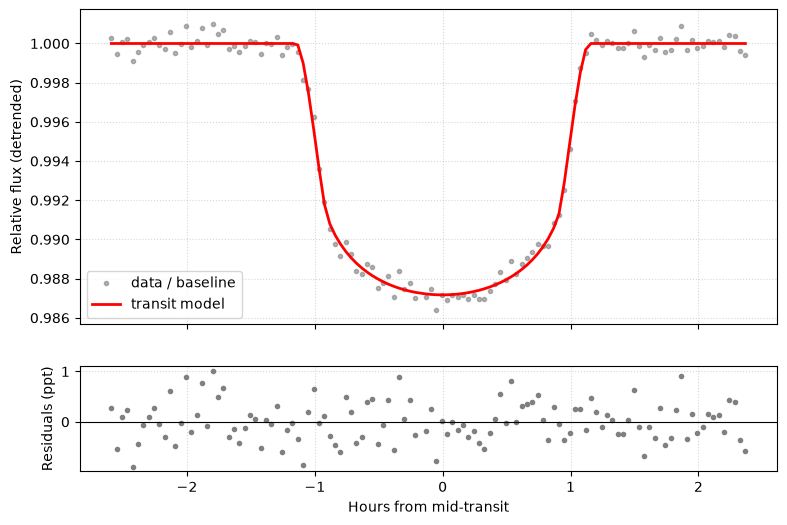

In [8]:
# transit is a dictionary: the fitted parameters are (median, upper error, lower error)
for name, (value, upper_error, lower_error) in transit["parameters"].items():
    print(f"{name:25s} {value:.5f}  +{upper_error:.5f} -{lower_error:.5f}")

print(f"\nDelta BIC (no transit - transit): {transit['delta_bic']:.1f}   (> 10: strong detection)")
print(f"Red-noise factor beta:            {transit['red_noise_factor']:.2f}   (1 = white noise)")
print(f"Scatter of the residuals:         {transit['residual_rms']*1e3:.2f} ppt per frame")

mid_transit_time = transit["parameters"]["mid_transit_time"][0]
hours = (transit["time"] - mid_transit_time)*24                # hours from mid-transit (only the frames used in the fit)
detrended_flux = transit["flux"]/transit["baseline"]           # data divided by the fitted baseline (time + airmass trend)
residuals = (detrended_flux - transit["transit_model"])*1e3    # in ppt (parts per thousand)

figure, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.plot(hours, detrended_flux, ".", color="gray", alpha=0.6, label="data / baseline")
top.plot(hours, transit["transit_model"], color="red", linewidth=2, label="transit model")
top.set_ylabel("Relative flux (detrended)")
top.legend()
bottom.plot(hours, residuals, ".", color="gray")
bottom.axhline(0, color="black", linewidth=0.8)
bottom.set_ylabel("Residuals (ppt)")
bottom.set_xlabel("Hours from mid-transit")
for axis in (top, bottom):
    axis.grid(linestyle=":", alpha=0.5)
plt.show()